# The realized EA/SW-IO forecast store on source.coop

[`ecmwf-ifs-ea-swio-realized-v3`](https://source.coop/e4drr-project/forecasts/ecmwf-ifs-ea-swio-realized-v3)
holds ECMWF IFS ensemble forecasts for East Africa and the south-west Indian
Ocean, **decoded and materialized** as an Icechunk store. It is built for **Continuous Risk Monitoring and Assessment (CRMA)**, for
**epistemic / Bayesian reasoning about risk**, and for training convective
models (**cGAN**) over the region.

All three depend on the same property: the store keeps **every one of the 51
ensemble members** rather than a mean. The spread between members *is* the
forecast uncertainty — the quantity a Bayesian treatment updates on, and the
distribution a cGAN learns to sample from. A deterministic store would have
discarded it.

It is a different kind of thing from the *virtual* GIK store
(`ecmwf_ifs_ens_aws_s3_icechunk_vd`), and the difference is what makes it easy
to use:

| | virtual store | **this store** |
|---|---|---|
| what a chunk is | a byte range in a GRIB file on AWS | **real float32 data** |
| domain | global, 721 x 1440 | **EA/SW-IO, 321 x 261** |
| variables | 19-59 raw ECMWF short names | **38 model-ready channels** |
| needs `gribberish` | yes, or opening fails | **no** |
| needs virtual-chunk auth | yes (`s3://ecmwf-forecasts/`) | **no** |
| needs credentials | no (but two anonymous hops) | **no** |

So: `icechunk` + `zarr` + `xarray`, anonymous, one hop. Nothing else.

Everything below is executed against the live store.


## Dependencies

```
icechunk>=2.1  zarr>=3.2  xarray>=2025.1  numpy  pandas  matplotlib
```

Note what is **absent**: no `gribberish`, no `s3fs`, no AWS credentials. The
chunks are ordinary compressed arrays.


In [1]:
# Dependency check -- this store needs no GRIB decoder, but it does need these.
import importlib, sys
need = ["icechunk", "zarr", "xarray", "boto3", "numpy", "pandas", "matplotlib"]
missing = [m for m in need if importlib.util.find_spec(m) is None]
if missing:
    print("MISSING:", ", ".join(missing))
    print("Install into THIS kernel with:")
    print(f"  %pip install {' '.join(missing)}")
    print(f"\nkernel: {sys.executable}")
else:
    print("all dependencies present")
    print("kernel:", sys.executable)

all dependencies present
kernel: /var/lib/nishadhka/grib-index-kerchunk/icechunk-dask-frisky/.venv/bin/python


In [2]:
%matplotlib inline
import asyncio
import time

import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import icechunk
import xarray as xr
from botocore import UNSIGNED
from botocore.config import Config

print("icechunk", icechunk.__version__)
print("xarray  ", xr.__version__)


icechunk 2.1.1
xarray   2026.7.0


## 1. Open a sub-store, anonymously

The store is split into **sub-stores, one per season**, because an Icechunk
store fixes its `time` axis at creation. Each is a separate repo under the same
prefix.

Four settings matter, and three of them are not obvious:

- `anonymous=True` — public read, no keys.
- `from_env=False` — ignore any `AWS_*` in the environment. Without this a
  stray `AWS_ENDPOINT_URL` silently redirects the open.
- `force_path_style=True` — source.coop needs path-style addressing.
- **manifest preload off** — the default open prefetches thousands of manifests
  in parallel, and source.coop returns sporadic 500s; one failure aborts the
  whole open.


In [3]:
ENDPOINT = "https://data.source.coop"
BUCKET   = "e4drr-project"
BASE     = "forecasts/ecmwf-ifs-ea-swio-realized-v3"


def open_sub(sub):
    """-> (repo, session, dataset) for one season sub-store. No credentials."""
    storage = icechunk.s3_storage(
        bucket=BUCKET, prefix=f"{BASE}/{sub}", endpoint_url=ENDPOINT,
        region="us-east-1",
        anonymous=True,          # public read
        from_env=False,          # ignore ambient AWS_* vars
        force_path_style=True,   # source.coop requires it
    )
    cfg = icechunk.RepositoryConfig.default()
    cfg.manifest = icechunk.ManifestConfig(
        preload=icechunk.ManifestPreloadConfig(max_total_refs=0,
                                               max_arrays_to_scan=0))
    repo = icechunk.Repository.open(storage, config=cfg)
    session = repo.readonly_session("main")
    # chunks={} is dask-backed and LAZY. chunks=None would load eagerly, and
    # concatenating two whole seasons would then try to allocate ~34 GiB.
    ds = xr.open_zarr(session.store, zarr_format=3, consolidated=False,
                      chunks={}, decode_timedelta=True)
    return repo, session, ds


t0 = time.time()
repo, sess, ds = open_sub("49r1-jja2025")
print(f"opened in {time.time() - t0:.1f}s\n")
print(ds)


opened in 3.5s

<xarray.Dataset> Size: 4TB
Dimensions:    (time: 92, step: 65, number: 51, latitude: 321, longitude: 261)
Coordinates:
  * time       (time) datetime64[ns] 736B 2025-06-01 2025-06-02 ... 2025-08-31
  * step       (step) timedelta64[s] 520B 0 days 00:00:00 ... 10 days 00:00:00
  * number     (number) int64 408B 0 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * latitude   (latitude) float64 3kB 40.0 39.75 39.5 ... -39.5 -39.75 -40.0
  * longitude  (longitude) float64 2kB 15.0 15.25 15.5 15.75 ... 79.5 79.75 80.0
Data variables: (12/38)
    cape       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    d700       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    d850       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    lsm        (time, step, number, latitude, longi

## 2. What seasons exist

List the sub-stores rather than assuming them — seasons are added over time.


In [4]:
s3 = boto3.client("s3", endpoint_url=ENDPOINT, region_name="us-east-1",
                  config=Config(signature_version=UNSIGNED,
                                s3={"addressing_style": "path"},
                                max_pool_connections=16))

r = s3.list_objects_v2(Bucket=BUCKET, Prefix=BASE + "/", Delimiter="/")
SUBS = sorted(p["Prefix"].split("/")[-2] for p in r.get("CommonPrefixes", []))
print(f"{len(SUBS)} sub-stores:")
for s in SUBS:
    print("   ", s)


8 sub-stores:
    49r1-jja2024
    49r1-jja2025
    49r1-mam2024
    49r1-mam2025
    49r1-mam2026
    50r1-jja2026
    50r1-jja2026-tail
    50r1-mam2026-tail


Read the names as `{era}-{season}{year}`:

- **era** — the ECMWF model cycle the source came from. `49r1` runs to
  2026-05-12; `50r1` from 2026-05-13. Grid and channels are identical across
  both, so the split is bookkeeping, not a data difference.
- **`-tail`** — a season that straddles an era boundary, or that ran past the
  end of the source at build time, continues in a second store. Section 6
  concatenates them.


## 3. Inventory: days, channels, size, history

`repo.ancestry()` walks the commit history — one commit per date written, so
the snapshot count is an audit trail of how the season was built. Object counts
and bytes come from listing the prefix.

This first table is metadata only and takes seconds. Bytes on disk are
a separate, optional step -- see below.


In [5]:
# Metadata only -- no object listing. A few seconds per sub-store.
rows = []
for sub in SUBS:
    repo_i, sess_i, ds_i = open_sub(sub)
    t = pd.to_datetime(ds_i.time.values)
    rows.append(dict(
        sub=sub, days=len(t), channels=len(ds_i.data_vars),
        steps=ds_i.sizes["step"], members=ds_i.sizes["number"],
        first=str(t.min().date()), last=str(t.max().date()),
        snapshots=len(list(repo_i.ancestry(branch="main"))),
    ))

inv = pd.DataFrame(rows)
print(inv.to_string(index=False))
print(f"\nTOTAL  {inv.days.sum()} forecast days across {len(inv)} sub-stores")

              sub  days  channels  steps  members      first       last  snapshots
     49r1-jja2024    92        38     65       51 2024-06-01 2024-08-31         94
     49r1-jja2025    92        38     65       51 2025-06-01 2025-08-31         94
     49r1-mam2024    92        38     65       51 2024-03-01 2024-05-31        291
     49r1-mam2025    92        38     65       51 2025-03-01 2025-05-31        187
     49r1-mam2026    73        38     65       51 2026-03-01 2026-05-12        224
     50r1-jja2026    33        38     65       51 2026-06-01 2026-07-03         35
50r1-jja2026-tail    51        38     65       51 2026-07-04 2026-08-23         53
50r1-mam2026-tail    19        38     65       51 2026-05-13 2026-05-31         41

TOTAL  544 forecast days across 8 sub-stores


### Optional: bytes on disk

The table above needs only metadata. Getting **actual stored bytes** means
listing every object -- about 1.4 million of them -- which is by far the
slowest thing in this notebook.

Two ways to avoid waiting:

- **Skip it.** Set `MEASURE_BYTES = False` and the published figures below are
  used instead. Everything else in the notebook still runs.
- **Measure it in parallel.** Listing is pure I/O, so running the eight
  sub-stores concurrently cuts it from ~25 minutes to ~3-4.

The published figures were measured on 2026-08-31 and only change when a new
season is added.

In [6]:
MEASURE_BYTES = False        # True -> list ~1.4M objects (~3-4 min, parallel)

# Measured 2026-08-31. Only changes when a season is added.
PUBLISHED_GB = {
    "49r1-mam2024": 1651.75, "49r1-mam2025": 1592.77, "49r1-mam2026": 1329.83,
    "50r1-mam2026-tail": 323.62, "49r1-jja2024": 1551.41, "49r1-jja2025": 1557.37,
    "50r1-jja2026": 560.09, "50r1-jja2026-tail": 857.06,
}

def prefix_bytes(sub):
    """Total bytes under one sub-store. One boto3 client per thread."""
    cl = boto3.client("s3", endpoint_url=ENDPOINT, region_name="us-east-1",
                      config=Config(signature_version=UNSIGNED,
                                    s3={"addressing_style": "path"},
                                    max_pool_connections=8))
    n = size = 0
    for page in cl.get_paginator("list_objects_v2").paginate(
            Bucket=BUCKET, Prefix=f"{BASE}/{sub}/"):
        for o in page.get("Contents", []):
            n += 1
            size += o["Size"]
    return sub, n, size

if MEASURE_BYTES:
    from concurrent.futures import ThreadPoolExecutor
    t1 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:          # 8 sub-stores at once
        measured = {s: (n, b) for s, n, b in ex.map(prefix_bytes, SUBS)}
    inv["objects"] = inv["sub"].map(lambda s: measured[s][0])
    inv["GB"] = inv["sub"].map(lambda s: round(measured[s][1] / 1e9, 2))
    print(f"listed {inv.objects.sum():,} objects in {time.time() - t1:.0f}s")
else:
    inv["GB"] = inv["sub"].map(PUBLISHED_GB)
    print("using published sizes (set MEASURE_BYTES = True to re-measure)")

print(inv[["sub", "days", "channels", "snapshots", "GB"]].to_string(index=False))
print(f"\nTOTAL  {inv.days.sum()} days   {inv.GB.sum() / 1000:.2f} TB")

using published sizes (set MEASURE_BYTES = True to re-measure)
              sub  days  channels  snapshots      GB
     49r1-jja2024    92        38         94 1551.41
     49r1-jja2025    92        38         94 1557.37
     49r1-mam2024    92        38        291 1651.75
     49r1-mam2025    92        38        187 1592.77
     49r1-mam2026    73        38        224 1329.83
     50r1-jja2026    33        38         35  560.09
50r1-jja2026-tail    51        38         53  857.06
50r1-mam2026-tail    19        38         41  323.62

TOTAL  544 days   9.42 TB


### Reading the numbers

**Days** is what most consumers want: how much forecast history is here. Each
day is a full 51-member ensemble out to 10 days.

**Snapshots exceed days** in some seasons. A season built in one clean pass has
roughly one commit per date; a higher count means dates were appended or
channels added later, and the history records it. Icechunk keeps that lineage,
so `ancestry()` is a real audit trail rather than a summary.


## 4. The 38 channels

Every sub-store carries the same 38, so a model trained on one season runs on
any other. They are derived from 18 base ECMWF variables at five pressure
levels (200, 500, 700, 850, 925 hPa) plus surface fields.


In [7]:
names = sorted(ds.data_vars)
print(f"{len(names)} channels\n")
for i in range(0, len(names), 8):
    print("   " + "  ".join(f"{n:<7}" for n in names[i:i + 8]))

print("\nshape of one channel:", ds["tp"].dims, ds["tp"].shape)
print("dtype:", ds["tp"].dtype)
print("chunking:", ds["tp"].encoding.get("chunks"))


38 channels

   cape     d200     d700     d850     gh500    lsm      msl      q500   
   q700     q850     q925     r700     r850     ro       skt      sp     
   t2m      t500     t700     t850     tcwv     tp       u10      u200   
   u500     u700     u850     u925     v10      v200     v500     v700   
   v850     v925     vo500    vo700    vo850    w700   

shape of one channel: ('time', 'step', 'number', 'latitude', 'longitude') (92, 65, 51, 321, 261)
dtype: float32
chunking: (1, 1, 51, 321, 261)


The chunk shape is the key to reading this efficiently: **one chunk holds all
51 members for a single (date, step)**. So asking for the whole ensemble at one
time and lead is one chunk fetch, while asking for one member across all dates
touches every chunk in the array. Select `time` and `step` first.

Channel naming: a bare name is a surface field (`tp`, `t2m`, `msl`), a trailing
number is the pressure level in hPa (`t850` is temperature at 850 hPa,
`u925` the zonal wind at 925). Two are worth calling out:

- **`cape`** — convective available potential energy. ECMWF renamed this field
  from `cape` to `mucape` on **2024-11-13**; both are stored under the single
  name `cape`, so a season straddling that date is one continuous channel.
- **`w700`** — vertical velocity at 700 hPa, the convective-ascent proxy.


## 5. Reading data

Ordinary xarray. The domain is EA/SW-IO on a 0.25 deg grid — note latitude
**descends**, which is the ECMWF convention and matters for `slice()`.


In [8]:
print("latitude :", float(ds.latitude[0]), "->", float(ds.latitude[-1]),
      f"({ds.sizes['latitude']} points, descending)")
print("longitude:", float(ds.longitude[0]), "->", float(ds.longitude[-1]),
      f"({ds.sizes['longitude']} points)")
steps_h = (pd.to_timedelta(ds.step.values) / pd.Timedelta("1h")).astype(int)
print("lead times:", list(steps_h[:6]), "...", list(steps_h[-3:]), "hours")
print("members   :", ds.sizes["number"], "(0 = control, 1-50 = perturbed)")


latitude : 40.0 -> -40.0 (321 points, descending)
longitude: 15.0 -> 80.0 (261 points)
lead times: [0, 3, 6, 9, 12, 15] ... [228, 234, 240] hours
members   : 51 (0 = control, 1-50 = perturbed)


In [9]:
# One field: whole ensemble, one date, one lead time -- a single chunk.
t1 = time.time()
date = ds.time.values[45]
tp = ds["tp"].sel(time=date).isel(step=8)          # all 51 members
print(f"tp, all members, {str(date)[:10]} +{int(steps_h[8])}h "
      f"-> {tp.shape} in {time.time() - t1:.2f}s")

ens_mean = tp.mean("number").compute() * 1000.0    # m -> mm
ens_sd   = tp.std("number").compute() * 1000.0
print(f"ensemble mean  {float(ens_mean.min()):.2f} .. {float(ens_mean.max()):.1f} mm")
print(f"ensemble sd    {float(ens_sd.min()):.2f} .. {float(ens_sd.max()):.1f} mm")


tp, all members, 2025-07-16 +24h -> (51, 321, 261) in 0.00s


ensemble mean  0.00 .. 115.4 mm
ensemble sd    0.00 .. 81.7 mm


### Adding coastlines and country borders

A contour plot of a bare array is hard to read without geography. `cartopy`
draws real coastlines and national boundaries from Natural Earth, which is the
better option when it is installed.

It is an extra dependency though, and one that needs GEOS/PROJ, so the helper
below **degrades gracefully**: without cartopy it contours the store's own
`lsm` (land-sea mask) channel at 0.5 to draw a coastline. That costs nothing
extra — `lsm` is one of the 38 channels and is constant in time — and it keeps
the notebook runnable on a bare `icechunk + xarray` environment.

In [10]:
# Map backdrop. cartopy gives real coastlines and country borders; if it is not
# installed we fall back to the store's own `lsm` (land-sea mask) channel, which
# contours to a serviceable coastline with no extra dependency at all.
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# lsm is constant in time -- read it once, whether or not we need it.
LSM = ds["lsm"].isel(time=0, step=0, number=0).compute()

print("cartopy:", "yes -- coastlines + country borders" if HAVE_CARTOPY
      else "no -- falling back to lsm coastline")


def make_ax(fig, pos):
    """One map axis, with a projection when cartopy is available."""
    if HAVE_CARTOPY:
        ax = fig.add_subplot(*pos, projection=ccrs.PlateCarree())
        ax.set_extent([float(ds.longitude[0]), float(ds.longitude[-1]),
                       float(ds.latitude[-1]), float(ds.latitude[0])],
                      crs=ccrs.PlateCarree())
    else:
        ax = fig.add_subplot(*pos)
        ax.set_aspect("equal")
    return ax


def add_boundaries(ax, color="0.25"):
    """Coastline and country borders, drawn on top of the field."""
    if HAVE_CARTOPY:
        # 50m is cached locally; nothing is downloaded at plot time.
        ax.add_feature(cfeature.COASTLINE.with_scale("50m"),
                       linewidth=0.6, edgecolor=color)
        ax.add_feature(cfeature.BORDERS.with_scale("50m"),
                       linewidth=0.4, edgecolor=color, alpha=0.7)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                          color="0.6", alpha=0.5, linestyle=":")
        gl.top_labels = gl.right_labels = False
    else:
        # lsm is 1 over land, 0 over sea -- the 0.5 contour is the coastline.
        ax.contour(LSM["longitude"], LSM["latitude"], LSM.values,
                   levels=[0.5], colors=color, linewidths=0.6)
        ax.set_xlabel("longitude (deg E)")
        ax.set_ylabel("latitude (deg N)")

cartopy: yes -- coastlines + country borders


In [11]:
fig = plt.figure(figsize=(15, 5.6))
for pos, fld, title, cmap in (
        ((1, 2, 1), ens_mean, "ensemble mean", "Blues"),
        ((1, 2, 2), ens_sd, "ensemble spread (sd)", "magma_r")):
    ax = make_ax(fig, pos)
    kw = dict(transform=ccrs.PlateCarree()) if HAVE_CARTOPY else {}
    m = ax.contourf(fld["longitude"], fld["latitude"], fld.values,
                    levels=21, cmap=cmap, **kw)
    add_boundaries(ax)
    ax.set_title(f"tp {title} -- {str(date)[:10]} +{int(steps_h[8])}h")
    fig.colorbar(m, ax=ax, label="mm", shrink=0.80, pad=0.06)

# NOTE: no plt.tight_layout() here. On cartopy GeoAxes it raises
#   GEOSException: Points of LinearRing do not form a closed linestring
# because it re-runs the layout after the map boundary is set. Use
# subplots_adjust, which does not re-trigger the projection clip.
fig.subplots_adjust(left=0.04, right=0.97, wspace=0.12)
plt.show()

GEOSException: IllegalArgumentException: Points of LinearRing do not form a closed linestring

<Figure size 1500x560 with 4 Axes>

That is the point of keeping all 51 members rather than a mean: the **spread**
is the signal a probabilistic model trains on. A deterministic store would have
thrown it away.


## 6. Seasons that span two stores

A season split across an era boundary, or extended after the source caught up,
lives in two sub-stores. Grid, steps and channels are identical, so
`xr.concat` on `time` is all that is needed.


In [12]:
pairs = [(s, s + "-tail") for s in SUBS if s + "-tail" in SUBS]
pairs += [(a, b) for a in SUBS for b in SUBS
          if b.endswith("-tail") and a.split("-", 1)[1] == b.split("-", 1)[1].replace("-tail", "")
          and (a, b) not in pairs]

for a, b in pairs:
    _, _, da = open_sub(a)
    _, _, db = open_sub(b)
    joined = xr.concat([da, db], dim="time")
    ta = pd.to_datetime(da.time.values)
    tb = pd.to_datetime(db.time.values)
    tj = pd.to_datetime(joined.time.values)
    print(f"{a:<20} {len(ta):>3} days  {ta.min().date()}..{ta.max().date()}")
    print(f"{b:<20} {len(tb):>3} days  {tb.min().date()}..{tb.max().date()}")
    print(f"{'-> concatenated':<20} {len(tj):>3} days  {tj.min().date()}..{tj.max().date()}"
          f"   monotonic: {tj.is_monotonic_increasing}\n")


50r1-jja2026          33 days  2026-06-01..2026-07-03
50r1-jja2026-tail     51 days  2026-07-04..2026-08-23
-> concatenated       84 days  2026-06-01..2026-08-23   monotonic: True



49r1-mam2026          73 days  2026-03-01..2026-05-12
50r1-mam2026-tail     19 days  2026-05-13..2026-05-31
-> concatenated       92 days  2026-03-01..2026-05-31   monotonic: True



## 7. Checking coverage — the trap

**The `time` axis is preallocated to the whole season.** A date that was never
written is therefore *not* absent: it is on the axis, `.sel()` finds it, and it
reads back as all-NaN. Nothing raises.

So `ds.sizes["time"]` tells you the axis length, not the coverage. Neither does
`.data_vars`. The manifest knows exactly which chunks exist, and
`session.chunk_coordinates` enumerates them **without fetching any of them**.


In [13]:
async def written_pairs(session, channel, attempts=5):
    """(time_idx, step_idx) this channel has chunks for. Manifest only.

    Retried: source.coop returns sporadic 500s and one mid-scan aborts the
    whole enumeration.
    """
    for attempt in range(attempts):
        try:
            out = set()
            async for c in session.chunk_coordinates(f"/{channel}"):
                out.add(tuple(c)[:2])
            return out
        except Exception:
            if attempt == attempts - 1:
                raise
            await asyncio.sleep(2 ** attempt)


sub = "49r1-jja2025"
repo_c, sess_c, ds_c = open_sub(sub)
nt, ns = ds_c.sizes["time"], ds_c.sizes["step"]

t1 = time.time()
have = await written_pairs(sess_c, "tp")   # top-level await: asyncio.run() raises in a kernel
days_with_data = len({t for t, _ in have})

print(f"{sub}: axis says {nt} days")
print(f"  chunks present for tp : {len(have):,} of {nt * ns:,} (date, step) pairs")
print(f"  days actually written : {days_with_data} of {nt}")
print(f"  -> {'COMPLETE' if len(have) == nt * ns else 'INCOMPLETE'}"
      f"   (manifest scan {time.time() - t1:.1f}s, no chunk data read)")


49r1-jja2025: axis says 92 days
  chunks present for tp : 5,980 of 5,980 (date, step) pairs
  days actually written : 92 of 92
  -> COMPLETE   (manifest scan 1.2s, no chunk data read)


In [14]:
# Confirm the manifest against the bytes: a written date is finite.
ti = sorted({t for t, _ in have})[0]
field = ds_c["t850"].isel(time=ti, step=1, number=0).values
print(f"t850 on {str(ds_c.time.values[ti])[:10]}: "
      f"finite fraction {np.isfinite(field).mean():.3f}, "
      f"range {np.nanmin(field):.1f}..{np.nanmax(field):.1f} K")


t850 on 2025-06-01: finite fraction 1.000, range 270.8..304.2 K


Use this whenever coverage matters. It is the only cheap way to tell a written
date from an unwritten one, and it reads the manifest rather than terabytes of
chunks.


## 8. How big is this, really

Three numbers, and only one of them answers *how much data is this*.


In [15]:
dense = 0
for sub in SUBS:
    _, _, d = open_sub(sub)
    dense += d.nbytes

stored = inv.GB.sum() / 1000.0        # TB actually hosted
days = int(inv.days.sum())
print(f"stored on source.coop      : {stored:8.2f} TB   <- what you download")
print(f"dense float32 (ds.nbytes)  : {dense/1e12:8.2f} TB   <- if uncompressed")
print(f"compression ratio          : {dense/1e12/stored:8.1f}x")
print()
print(f"forecast days              : {days:8d}")
print(f"per forecast day           : {stored*1000/days:8.1f} GB")
print("  = 38 channels x 51 members x 65 steps x 321 x 261 float32")

stored on source.coop      :     9.42 TB   <- what you download
dense float32 (ds.nbytes)  :    22.97 TB   <- if uncompressed
compression ratio          :      2.4x

forecast days              :      544
per forecast day           :     17.3 GB
  = 38 channels x 51 members x 65 steps x 321 x 261 float32


`ds.nbytes` describes a dense in-memory array that does not exist on disk —
quote the **stored** figure. Per forecast day is the number to plan with: it
tells you what one more season costs.


## 9. A worked example: rainfall over one point

Everything together — pick a location, pull the full ensemble across lead
times, and look at how the forecast spread grows.


pulled (65, 51) (members x steps) in 47.3s


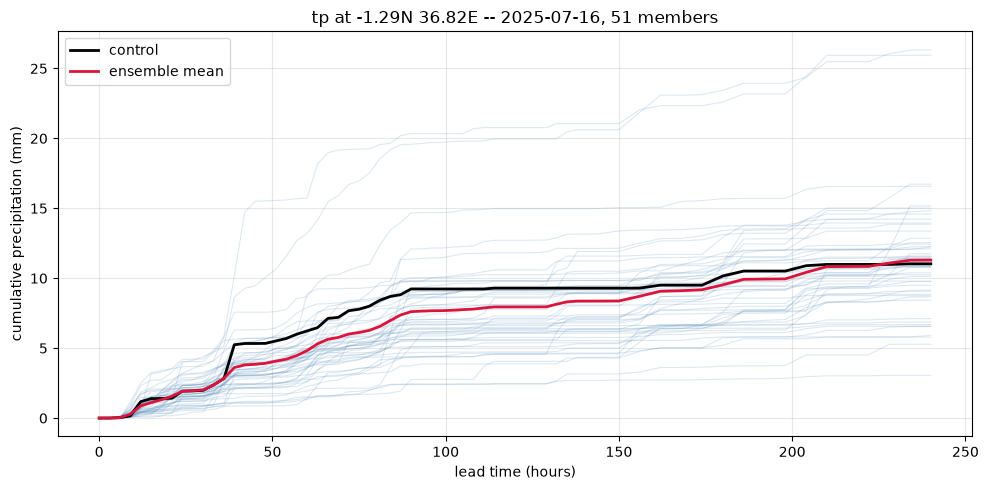

In [16]:
LAT, LON = -1.29, 36.82        # Nairobi
_, _, dj = open_sub("49r1-jja2025")

t1 = time.time()
series = (dj["tp"]
          .sel(latitude=LAT, longitude=LON, method="nearest")
          .isel(time=45)
          .compute()) * 1000.0        # m -> mm, cumulative
print(f"pulled {series.shape} (members x steps) in {time.time() - t1:.1f}s")

lead = (pd.to_timedelta(dj.step.values) / pd.Timedelta("1h")).astype(int)
fig, ax = plt.subplots(figsize=(10, 5))
for m in range(series.sizes["number"]):
    ax.plot(lead, series.isel(number=m), color="steelblue", alpha=0.18, lw=0.8)
ax.plot(lead, series.isel(number=0), color="black", lw=2, label="control")
ax.plot(lead, series.mean("number"), color="crimson", lw=2, label="ensemble mean")
ax.set_xlabel("lead time (hours)")
ax.set_ylabel("cumulative precipitation (mm)")
ax.set_title(f"tp at {LAT}N {LON}E -- {str(dj.time.values[45])[:10]}, 51 members")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Gotchas

- **Open per sub-store, not once.** Each season is its own Icechunk repo. Use
  `xr.concat` to join a season split across two (section 6).
- **The `time` axis is preallocated.** An unwritten date reads as all-NaN and
  does not raise. Check coverage with `session.chunk_coordinates`, never with
  `ds.sizes["time"]` (section 7).
- **Latitude descends** (40N -> -40S). `slice(-10, 10)` returns nothing; you
  want `slice(10, -10)`.
- **Select `time` and `step` before computing.** One chunk is all 51 members at
  one (date, step); a careless selection across dates touches every chunk.
- **`from_env=False` is not optional.** Without it a stray `AWS_ENDPOINT_URL`
  in your environment silently redirects the open to the wrong host.
- **Disable the manifest preload**, or a sporadic source.coop 500 fails the
  open outright.
- **Retry manifest scans.** The same 500s abort a `chunk_coordinates`
  enumeration partway.
- **`cape` spans a rename.** ECMWF switched `cape` -> `mucape` on 2024-11-13;
  both are stored under `cape`, so no consumer action is needed — but a season
  crossing that date is the one to spot-check if values look wrong.
- **Do not quote `ds.nbytes`** as the data volume; it is the uncompressed dense
  size, several times what is stored.
